# PRAICP-1003 – Air Temperature Time Series Forecasting
**DataMites™ Project Mentoring – Data Science Project (PR-0019)**

**Business case:** Develop a machine learning model that can forecast the monthly mean air temperature for the coming months.

**Project goal:** Build an ML / time-series model to forecast the monthly means of air temperature.

**Dataset:** Monthly mean surface air temperature (°C) recorded at the Changi Climate Station, Singapore (National Environment Agency), Jan 1982 – Jun 2020.

| Feature | Description |
|---|---|
| `month` | Month for which the mean temperature is recorded (YYYY-MM) |
| `mean_temp` | Average air temperature for the month (°C) |

**Workflow:** 1) Load data → 2) Data checks → 3) EDA → 4) Stationarity & ACF/PACF → 5) Train/test split → 6) Baseline, Holt-Winters, ARIMA, SARIMA, ML (lag-feature) models → 7) Model comparison → 8) Final model, residual check, 12-month forecast → 9) Save model → 10) Conclusion

## 1. Import Libraries

In [1]:
import warnings, itertools, os, joblib
warnings.simplefilter("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
RANDOM_STATE = 42

## 2. Load the Dataset

In [2]:
candidates = ["Data/surface-air-temperature-monthly-mean.csv",
              "surface-air-temperature-monthly-mean.csv",
              "/mnt/user-data/uploads/Data/surface-air-temperature-monthly-mean.csv",
              "/home/claude/data/Data/surface-air-temperature-monthly-mean.csv"]
path = next(p for p in candidates if os.path.exists(p))
df = pd.read_csv(path)
print("Loaded from:", path)
print("Shape:", df.shape)
df.head()

Loaded from: /home/claude/data/Data/surface-air-temperature-monthly-mean.csv
Shape: (462, 2)


,month,mean_temp
0,1982-01,25.9
1,1982-02,27.1
2,1982-03,27.2
3,1982-04,27.0
4,1982-05,28.0


## 3. Data Understanding & Quality Checks

In [3]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate months:", df["month"].duplicated().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 462 entries, 0 to 461
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   month      462 non-null    str    
 1   mean_temp  462 non-null    float64
dtypes: float64(1), str(1)
memory usage: 7.3 KB

Missing values:
 month        0
mean_temp    0
dtype: int64

Duplicate months: 0


,mean_temp
count,462.000000
mean,27.665152
std,0.808186
min,25.400000
25%,27.100000
50%,27.700000
75%,28.300000
max,29.500000


In [4]:
# Convert 'month' to datetime and use it as a monthly index
df["month"] = pd.to_datetime(df["month"], format="%Y-%m")
df = df.sort_values("month").set_index("month")
df.index.freq = "MS"          # month-start frequency

# Check that there are no gaps in the monthly series
full_range = pd.date_range(df.index.min(), df.index.max(), freq="MS")
print("Date range:", df.index.min().date(), "->", df.index.max().date())
print("Expected months:", len(full_range), "| Available months:", len(df), "| Missing months:", len(full_range.difference(df.index)))

ts = df["mean_temp"]

Date range: 1982-01-01 -> 2020-06-01
Expected months: 462 | Available months: 462 | Missing months: 0


## 4. Exploratory Data Analysis

### 4.1 Time series plot

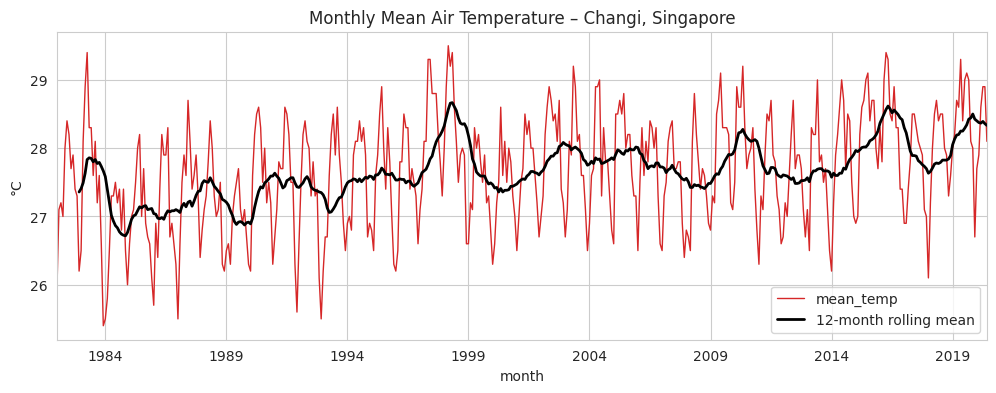

In [5]:
fig, ax = plt.subplots()
ts.plot(ax=ax, color="tab:red", lw=1)
ts.rolling(12).mean().plot(ax=ax, color="black", lw=2, label="12-month rolling mean")
ax.set_title("Monthly Mean Air Temperature – Changi, Singapore")
ax.set_ylabel("°C"); ax.legend()
plt.show()

### 4.2 Distribution

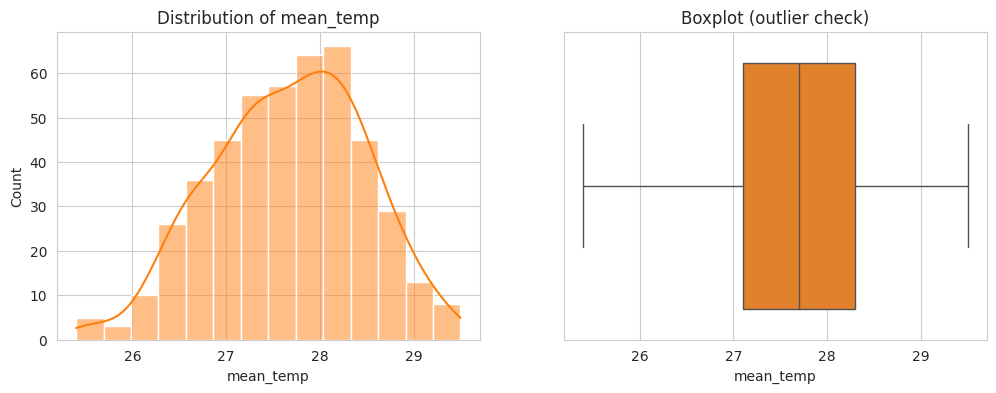

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(ts, kde=True, ax=axes[0], color="tab:orange"); axes[0].set_title("Distribution of mean_temp")
sns.boxplot(x=ts, ax=axes[1], color="tab:orange");           axes[1].set_title("Boxplot (outlier check)")
plt.show()

### 4.3 Seasonality – by month and by year

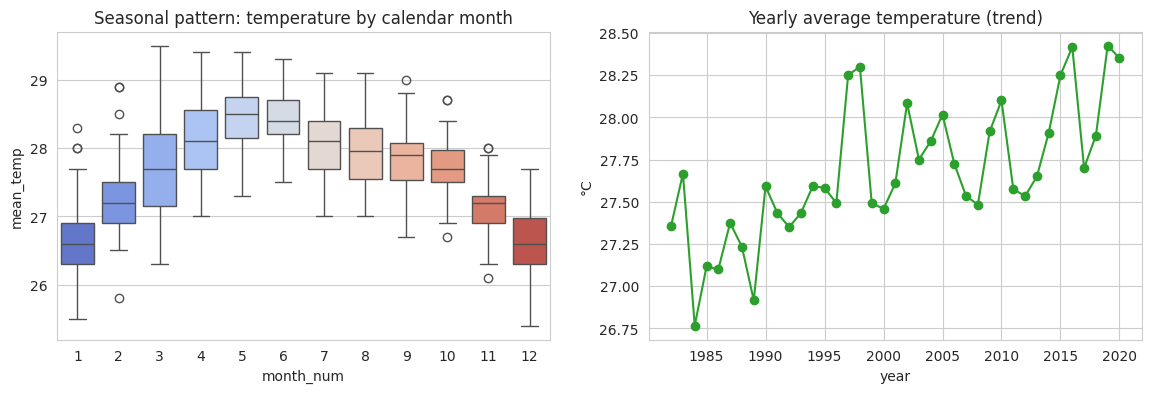

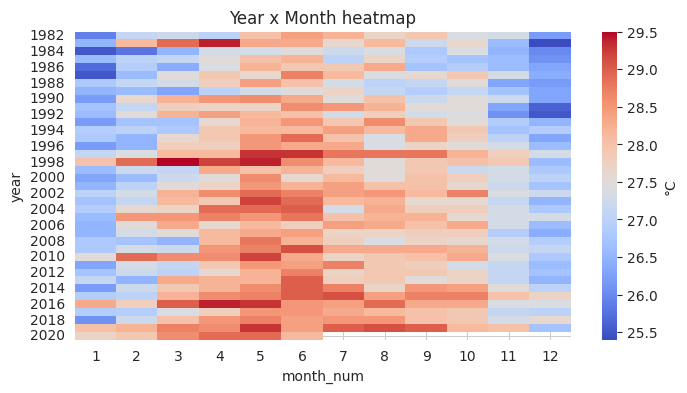

In [7]:
tmp = ts.to_frame()
tmp["year"], tmp["month_num"] = tmp.index.year, tmp.index.month

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=tmp, x="month_num", y="mean_temp", ax=axes[0], palette="coolwarm")
axes[0].set_title("Seasonal pattern: temperature by calendar month")
tmp.groupby("year")["mean_temp"].mean().plot(ax=axes[1], marker="o", color="tab:green")
axes[1].set_title("Yearly average temperature (trend)"); axes[1].set_ylabel("°C")
plt.show()

plt.figure(figsize=(8, 4))
sns.heatmap(tmp.pivot_table(index="year", columns="month_num", values="mean_temp"), cmap="coolwarm", cbar_kws={"label": "°C"})
plt.title("Year x Month heatmap"); plt.show()

### 4.4 Decomposition (trend + seasonality + residual)

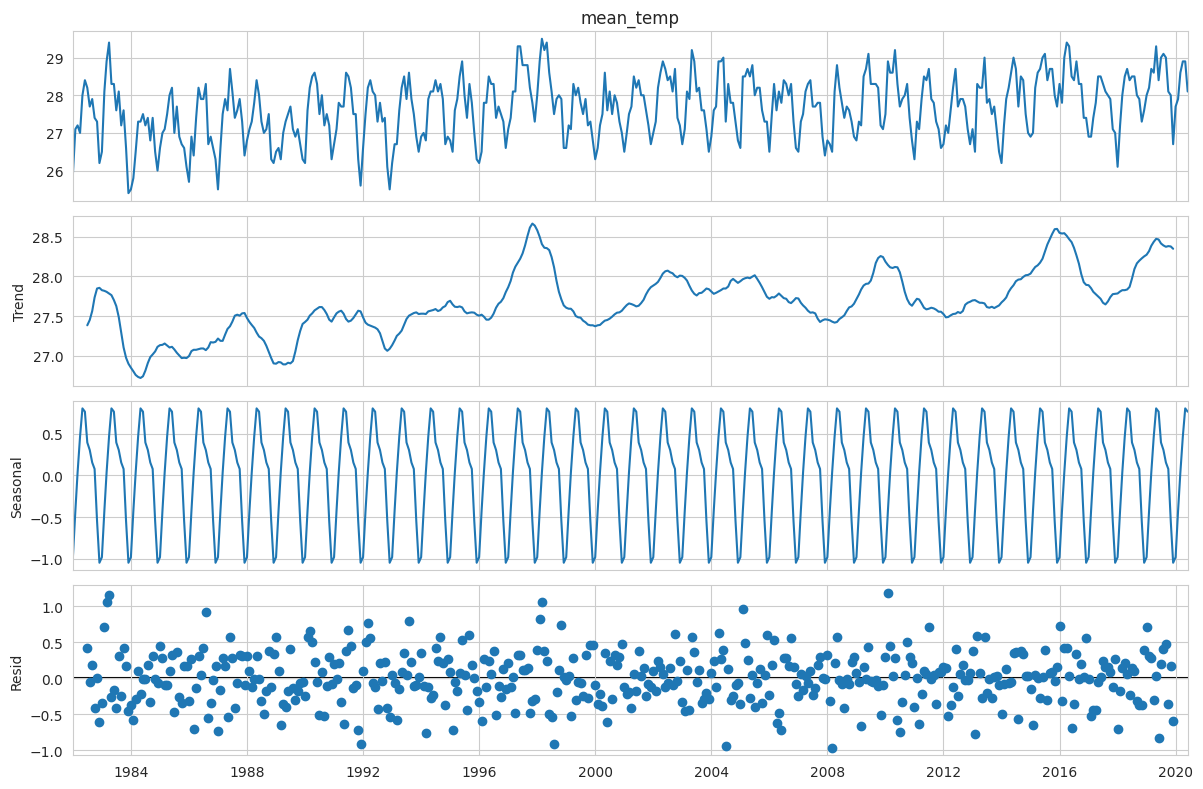

In [8]:
decomp = seasonal_decompose(ts, model="additive", period=12)
fig = decomp.plot(); fig.set_size_inches(12, 8); plt.tight_layout(); plt.show()

**EDA observations**
- The series is complete (no missing months, no duplicates).
- There is a clear **yearly seasonality** (period = 12): temperatures are lowest around Dec–Jan (monsoon) and peak around May–June.
- There is a mild **upward trend** over the decades (warming).
- Seasonal swings look roughly constant in size, so an **additive** model is appropriate.

## 5. Stationarity Tests & ACF / PACF

In [9]:
def stationarity_report(series, name):
    adf_p  = adfuller(series.dropna(), autolag="AIC")[1]
    kpss_p = kpss(series.dropna(), regression="c", nlags="auto")[1]
    print(f"{name:<28} ADF p-value = {adf_p:.4f} ({'stationary' if adf_p<0.05 else 'non-stationary'}) | "
          f"KPSS p-value = {kpss_p:.4f} ({'stationary' if kpss_p>0.05 else 'non-stationary'})")

stationarity_report(ts, "Original")
stationarity_report(ts.diff(1), "1st difference (d=1)")
stationarity_report(ts.diff(12), "Seasonal diff (D=1, m=12)")
stationarity_report(ts.diff(12).diff(1), "Seasonal + regular diff")

Original                     ADF p-value = 0.0005 (stationary) | KPSS p-value = 0.0100 (non-stationary)
1st difference (d=1)         ADF p-value = 0.0000 (stationary) | KPSS p-value = 0.1000 (stationary)
Seasonal diff (D=1, m=12)    ADF p-value = 0.0000 (stationary) | KPSS p-value = 0.1000 (stationary)
Seasonal + regular diff      ADF p-value = 0.0000 (stationary) | KPSS p-value = 0.1000 (stationary)


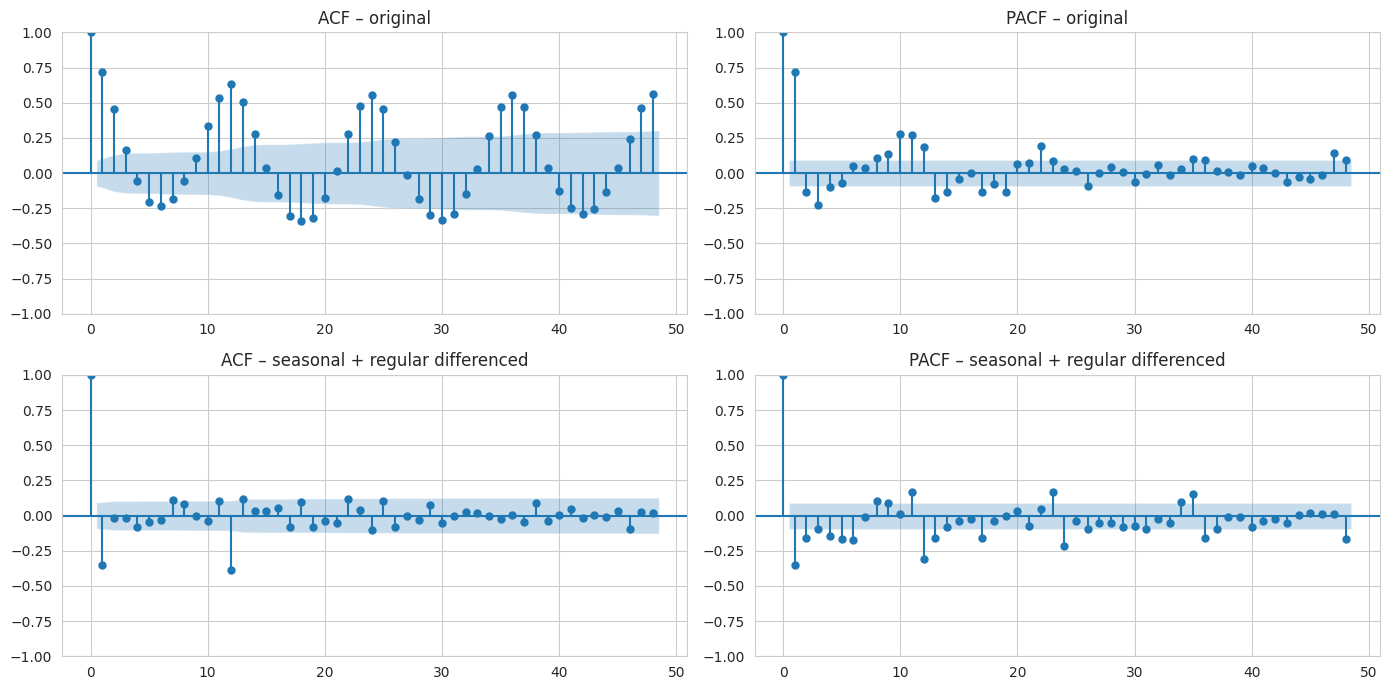

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(ts, lags=48, ax=axes[0,0]);  axes[0,0].set_title("ACF – original")
plot_pacf(ts, lags=48, ax=axes[0,1]); axes[0,1].set_title("PACF – original")
d = ts.diff(12).diff(1).dropna()
plot_acf(d, lags=48, ax=axes[1,0]);   axes[1,0].set_title("ACF – seasonal + regular differenced")
plot_pacf(d, lags=48, ax=axes[1,1]);  axes[1,1].set_title("PACF – seasonal + regular differenced")
plt.tight_layout(); plt.show()

The ACF shows a strong 12-month cycle, confirming seasonality, so the models below use a seasonal period of **m = 12**.

## 6. Train / Test Split
Time series must be split **chronologically** (no shuffling). The last **24 months** are held out as the test set.

In [11]:
TEST_SIZE = 24
train, test = ts.iloc[:-TEST_SIZE], ts.iloc[-TEST_SIZE:]
print("Train:", train.index.min().date(), "->", train.index.max().date(), len(train))
print("Test :", test.index.min().date(),  "->", test.index.max().date(),  len(test))

def evaluate(y_true, y_pred, name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {"Model": name, "RMSE": rmse, "MAE": mae, "MAPE %": mape}

results, forecasts = [], {}

Train: 1982-01-01 -> 2018-06-01 438
Test : 2018-07-01 -> 2020-06-01 24


## 7. Model Building

### 7.1 Baseline models
Any useful model must beat these simple benchmarks.

In [12]:
# Naive: repeat last observed value
naive = pd.Series(train.iloc[-1], index=test.index)
# Seasonal naive: repeat the last observed 12-month cycle
snaive = pd.Series(np.tile(train.iloc[-12:].values, TEST_SIZE // 12 + 1)[:TEST_SIZE], index=test.index)
# Seasonal mean: average of that calendar month over the training years
month_avg = train.groupby(train.index.month).mean()
smean = pd.Series(test.index.month.map(month_avg).values, index=test.index)

for name, f in [("Naive", naive), ("Seasonal Naive", snaive), ("Seasonal Mean", smean)]:
    results.append(evaluate(test, f, name)); forecasts[name] = f
pd.DataFrame(results)

,Model,RMSE,MAE,MAPE %
0,Naive,0.617117,0.500000,1.781555
1,Seasonal Naive,0.741620,0.566667,2.002289
2,Seasonal Mean,0.792752,0.691811,2.434359


### 7.2 Holt-Winters (Triple Exponential Smoothing)

In [13]:
hw_configs = {}
for trend, seasonal, damped in itertools.product(["add", None], ["add", "mul"], [False, True]):
    if trend is None and damped: continue
    try:
        m = ExponentialSmoothing(train, trend=trend, seasonal=seasonal, seasonal_periods=12,
                                 damped_trend=damped, initialization_method="estimated").fit()
        hw_configs[(trend, seasonal, damped)] = (m.aic, m)
    except Exception as e:
        pass

hw_table = pd.DataFrame([{"trend": k[0], "seasonal": k[1], "damped": k[2], "AIC": v[0]} for k, v in hw_configs.items()]).sort_values("AIC")
display(hw_table)

best_hw_key = hw_table.iloc[0][["trend", "seasonal", "damped"]].tolist()
best_hw_key = tuple(None if pd.isna(x) else x for x in best_hw_key)
hw_model = hw_configs[best_hw_key][1]
hw_fc = hw_model.forecast(TEST_SIZE)
results.append(evaluate(test, hw_fc, "Holt-Winters")); forecasts["Holt-Winters"] = hw_fc
print("Best config (selected on training AIC):", best_hw_key)

,trend,seasonal,damped,AIC
4,NaN,add,False,-751.823127
5,NaN,mul,False,-749.818118
0,add,add,False,-747.861127
1,add,add,True,-747.029166
2,add,mul,False,-745.857176
3,add,mul,True,-745.122455


Best config (selected on training AIC): (None, 'add', np.False_)


### 7.3 ARIMA (non-seasonal)

In [14]:
best = (np.inf, None)
for p, d, q in itertools.product(range(0, 4), [0, 1], range(0, 4)):
    try:
        m = SARIMAX(train, order=(p, d, q)).fit(disp=False)
        if m.aic < best[0]: best = (m.aic, (p, d, q))
    except Exception: pass
print("Best ARIMA order by AIC:", best[1], "| AIC =", round(best[0], 2))
arima_model = SARIMAX(train, order=best[1]).fit(disp=False)
arima_fc = arima_model.get_forecast(TEST_SIZE).predicted_mean
results.append(evaluate(test, arima_fc, f"ARIMA{best[1]}")); forecasts[f"ARIMA{best[1]}"] = arima_fc

Best ARIMA order by AIC: (3, 1, 3) | AIC = 692.62


### 7.4 SARIMA (seasonal ARIMA, m = 12)
Grid search over a small set of (p,d,q)(P,D,Q,12) orders, selected on training AIC.

In [15]:
pdq  = [(p, d, q) for p in range(0, 3) for d in [0, 1] for q in range(0, 3)]
PDQ  = [(P, 1, Q, 12) for P in range(0, 2) for Q in range(0, 2)]
sarima_res = []
for order in pdq:
    for sorder in PDQ:
        try:
            m = SARIMAX(train, order=order, seasonal_order=sorder,
                        enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            sarima_res.append((order, sorder, m.aic))
        except Exception: pass

sarima_tbl = pd.DataFrame(sarima_res, columns=["order", "seasonal_order", "AIC"]).sort_values("AIC")
display(sarima_tbl.head(8))
best_order, best_sorder = sarima_tbl.iloc[0]["order"], sarima_tbl.iloc[0]["seasonal_order"]

sarima_model = SARIMAX(train, order=best_order, seasonal_order=best_sorder,
                       enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
sarima_fc = sarima_model.get_forecast(TEST_SIZE).predicted_mean
name = f"SARIMA{best_order}x{best_sorder}"
results.append(evaluate(test, sarima_fc, name)); forecasts[name] = sarima_fc
print(sarima_model.summary().tables[1])

,order,seasonal_order,AIC
33,"(1, 0, 2)","(0, 1, 1, 12)",447.444448
57,"(2, 0, 2)","(0, 1, 1, 12)",448.127816
35,"(1, 0, 2)","(1, 1, 1, 12)",449.444771
53,"(2, 0, 1)","(0, 1, 1, 12)",449.587381
29,"(1, 0, 1)","(0, 1, 1, 12)",449.631494
59,"(2, 0, 2)","(1, 1, 1, 12)",450.133534
55,"(2, 0, 1)","(1, 1, 1, 12)",451.587777
31,"(1, 0, 1)","(1, 1, 1, 12)",451.631851


                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9268      0.025     37.352      0.000       0.878       0.975
ma.L1         -0.5558      0.054    -10.282      0.000      -0.662      -0.450
ma.L2         -0.0762      0.054     -1.415      0.157      -0.182       0.029
ma.S.L12      -0.9535      0.049    -19.652      0.000      -1.049      -0.858
sigma2         0.1614      0.013     12.048      0.000       0.135       0.188


### 7.5 Machine-learning models with lag features
The time series is converted into a supervised-learning problem using **lag features** (previous 1, 2, 3, 6, 12 months), a rolling mean and **cyclic month encodings**. Forecasts are made **recursively** (each predicted value is fed back as input), which mimics real multi-step forecasting and avoids data leakage.

In [16]:
LAGS = [1, 2, 3, 6, 12]

def make_features(history: pd.Series, date):
    """Build one feature row for `date` using only data strictly before it."""
    row = {f"lag_{l}": history.loc[date - pd.DateOffset(months=l)] for l in LAGS}
    row["roll_mean_3"]  = np.mean([history.loc[date - pd.DateOffset(months=i)] for i in range(1, 4)])
    row["roll_mean_12"] = np.mean([history.loc[date - pd.DateOffset(months=i)] for i in range(1, 13)])
    row["month_sin"] = np.sin(2 * np.pi * date.month / 12)
    row["month_cos"] = np.cos(2 * np.pi * date.month / 12)
    return row

def build_supervised(series):
    idx = series.index[12:]
    X = pd.DataFrame([make_features(series, d) for d in idx], index=idx)
    return X, series.loc[idx]

def recursive_forecast(model, history, steps):
    hist = history.copy()
    preds = []
    for _ in range(steps):
        d = hist.index[-1] + pd.DateOffset(months=1)
        x = pd.DataFrame([make_features(hist, d)])
        yhat = float(model.predict(x)[0])
        hist.loc[d] = yhat
        preds.append((d, yhat))
    return pd.Series([p[1] for p in preds], index=[p[0] for p in preds])

X_train, y_train = build_supervised(train)
ml_models = {
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1),
}
for name, mdl in ml_models.items():
    mdl.fit(X_train, y_train)
    fc = recursive_forecast(mdl, train, TEST_SIZE); fc.index = test.index
    results.append(evaluate(test, fc, name)); forecasts[name] = fc

## 8. Model Comparison

In [17]:
res = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(res.style.format({"RMSE": "{:.3f}", "MAE": "{:.3f}", "MAPE %": "{:.2f}"}).background_gradient(cmap="RdYlGn_r", subset=["RMSE", "MAE", "MAPE %"]))

best_name = res.loc[0, "Model"]
print("Best model on the test set:", best_name)

,Model,RMSE,MAE,MAPE %
0,Naive,0.617,0.500,1.78
1,Holt-Winters,0.679,0.578,2.03
2,"ARIMA(3, 1, 3)",0.681,0.539,1.89
3,Random Forest,0.710,0.620,2.18
4,"SARIMA(1, 0, 2)x(0, 1, 1, 12)",0.710,0.605,2.13
5,Seasonal Naive,0.742,0.567,2.00
6,Ridge Regression,0.742,0.662,2.33
7,Seasonal Mean,0.793,0.692,2.43


Best model on the test set: Naive


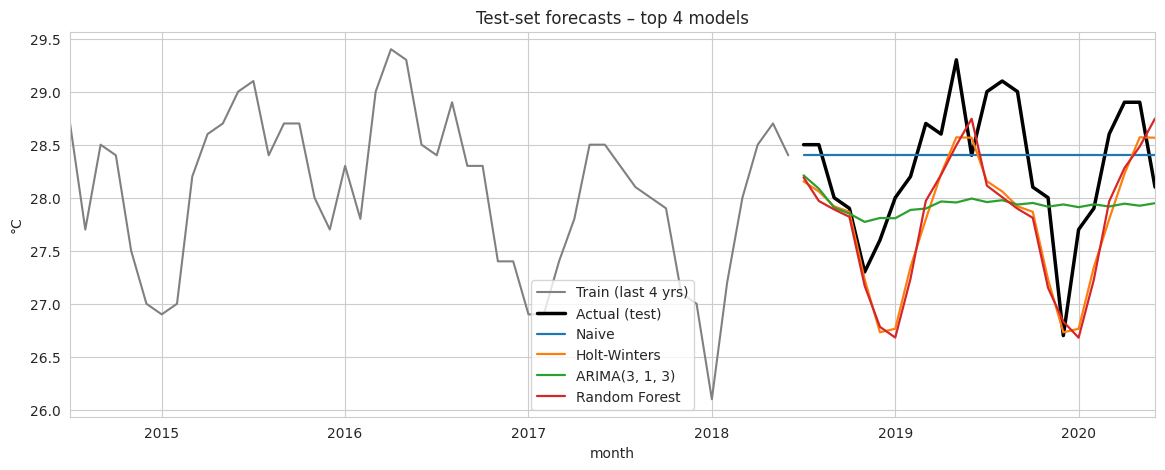

In [18]:
fig, ax = plt.subplots(figsize=(14, 5))
train.iloc[-48:].plot(ax=ax, color="gray", label="Train (last 4 yrs)")
test.plot(ax=ax, color="black", lw=2.5, label="Actual (test)")
for name in res["Model"].head(4):
    forecasts[name].plot(ax=ax, label=name, lw=1.6)
ax.set_title("Test-set forecasts – top 4 models"); ax.set_ylabel("°C"); ax.legend()
plt.show()

**Caution:** a single 24-month hold-out is a noisy yardstick. The seasonal swing in this series (about ±0.5 °C) is small compared with year-to-year variation, so a "flat" Naive forecast can look good by luck on one particular window. To compare models fairly we use **rolling-origin cross-validation** below.

### 8.1 Rolling-origin cross-validation (5 folds x 12-month horizon)\nEach fold trains only on data before the fold and forecasts the next 12 months. Model orders found above are kept fixed; models are re-fitted on every fold.

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean RMSE,Std
Holt-Winters,0.675,0.601,0.292,0.636,0.487,0.538,0.155
SARIMA,0.830,0.395,0.275,0.660,0.562,0.544,0.218
Ridge Regression,0.814,0.499,0.376,0.676,0.526,0.578,0.170
Random Forest,0.920,0.731,0.292,0.658,0.506,0.621,0.237
Seasonal Naive,0.708,0.915,0.481,0.711,0.539,0.671,0.170
Seasonal Mean,1.071,0.497,0.295,0.748,0.820,0.686,0.299
ARIMA,0.898,0.586,0.693,0.555,0.781,0.703,0.141
Naive,0.687,0.889,1.032,0.534,0.690,0.767,0.195


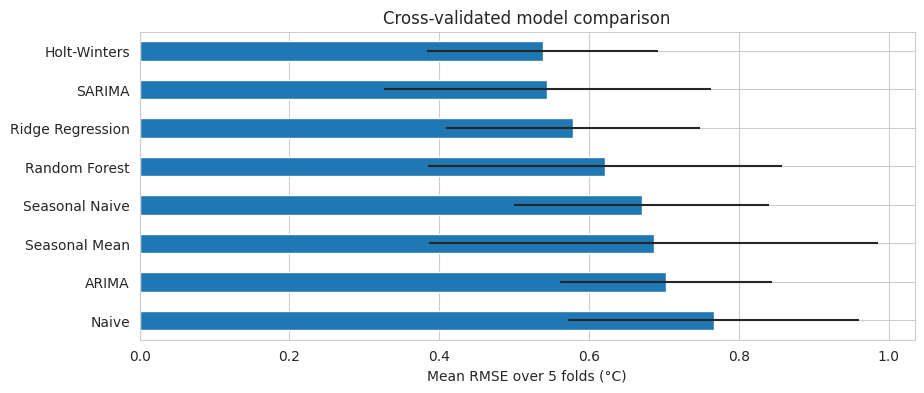

In [19]:
H, N_FOLDS = 12, 5
cv_scores = {}

def sarima_fit(tr):  return SARIMAX(tr, order=best_order, seasonal_order=best_sorder,
                                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

for k in range(N_FOLDS, 0, -1):
    tr = ts.iloc[:len(ts) - H * k]
    te = ts.iloc[len(ts) - H * k: len(ts) - H * (k - 1)]
    P = {}
    P["Naive"]          = np.repeat(tr.iloc[-1], H)
    P["Seasonal Naive"] = tr.iloc[-12:].values
    P["Seasonal Mean"]  = te.index.month.map(tr.groupby(tr.index.month).mean()).values
    P["Holt-Winters"]   = ExponentialSmoothing(tr, trend=best_hw_key[0], seasonal=best_hw_key[1], seasonal_periods=12,
                                               damped_trend=bool(best_hw_key[2]) if best_hw_key[0] else False,
                                               initialization_method="estimated").fit().forecast(H).values
    P["ARIMA"]          = SARIMAX(tr, order=best[1]).fit(disp=False).forecast(H).values
    P["SARIMA"]         = sarima_fit(tr).forecast(H).values
    Xf, yf = build_supervised(tr)
    for n, proto in ml_models.items():
        from sklearn.base import clone
        m = clone(proto).fit(Xf, yf)
        P[n] = recursive_forecast(m, tr, H).values
    for n, p in P.items():
        cv_scores.setdefault(n, []).append(np.sqrt(mean_squared_error(te.values, p)))

cv_df = pd.DataFrame(cv_scores).T
cv_df.columns = [f"Fold {i+1}" for i in range(N_FOLDS)]
cv_df["Mean RMSE"] = cv_df.mean(axis=1)
cv_df["Std"] = cv_df.iloc[:, :N_FOLDS].std(axis=1)
cv_df = cv_df.sort_values("Mean RMSE")
display(cv_df.style.format("{:.3f}").background_gradient(cmap="RdYlGn_r", subset=["Mean RMSE"]))

fig, ax = plt.subplots(figsize=(10, 4))
cv_df["Mean RMSE"].sort_values(ascending=False).plot.barh(ax=ax, color="tab:blue", xerr=cv_df["Std"].reindex(cv_df["Mean RMSE"].sort_values(ascending=False).index))
ax.set_xlabel("Mean RMSE over 5 folds (°C)"); ax.set_title("Cross-validated model comparison")
plt.show()

**Reading the CV results:** over five different 12-month windows, the seasonal models (**Holt-Winters** and **SARIMA**) are the most accurate and are close to each other, while the Naive forecast is among the worst (it ignores the seasonal cycle). The earlier single split, where Naive ranked first, was not reliable. We pick **SARIMA** as the final model: its accuracy is on par with Holt-Winters, and it gives proper prediction intervals and residual diagnostics.

## 9. Final Model, Diagnostics & Forecast
The final model is chosen using the **cross-validated RMSE** (Section 8.1), not the single split. SARIMA is tied with Holt-Winters for best accuracy and is chosen because it also provides prediction intervals and residual diagnostics. It is **re-fitted on the full data (1982-01 → 2020-06)** and used to forecast the next 12 months.

CV mean RMSE -> SARIMA: 0.544 | Holt-Winters: 0.538 | Naive: 0.767


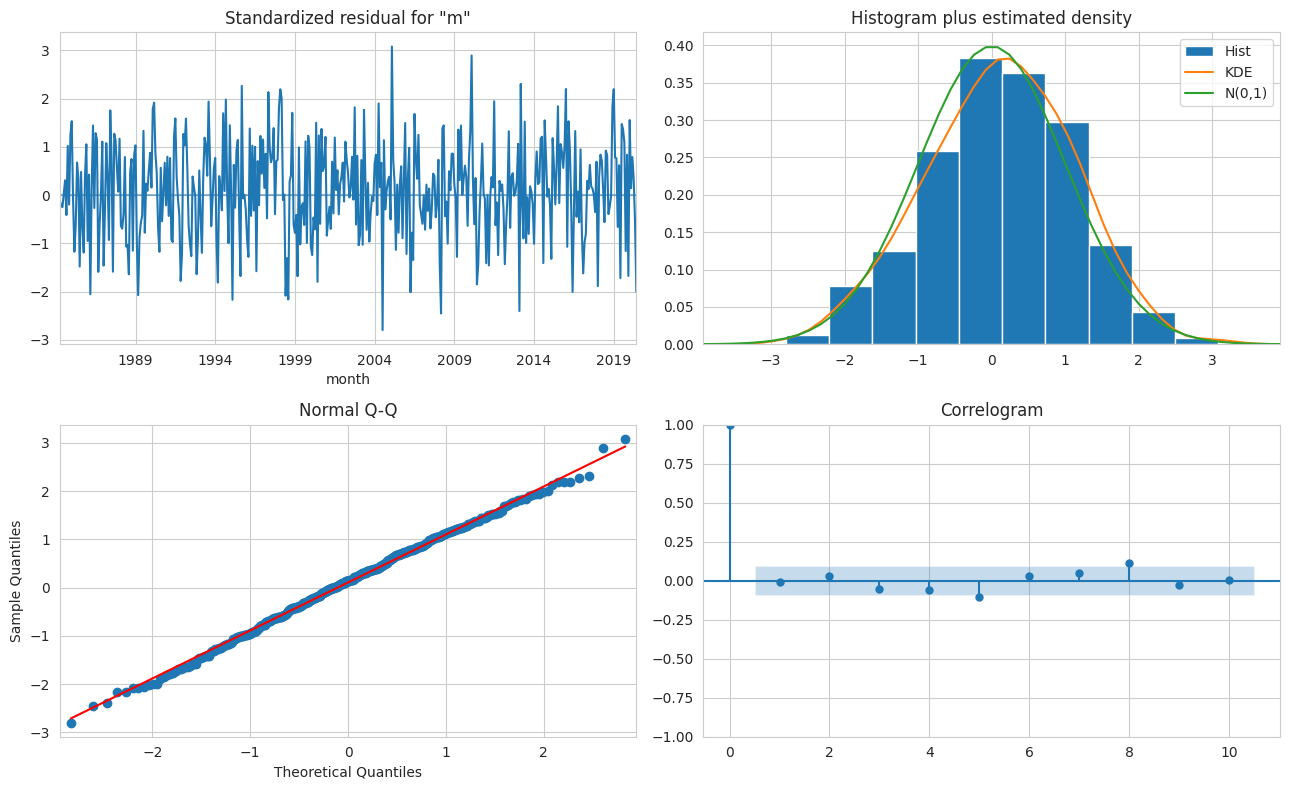

,lb_stat,lb_pvalue
12,24.960628,0.015011
24,39.722215,0.022902


Ljung-Box p-values below 0.05 mean some autocorrelation remains in the residuals, i.e. the model does not capture every pattern (e.g. multi-year climate swings). Forecast intervals should therefore be treated as approximate.


In [20]:
# Re-fit SARIMA on the full history for the production forecast.
print("CV mean RMSE -> SARIMA: %.3f | Holt-Winters: %.3f | Naive: %.3f" %
      (cv_df.loc["SARIMA", "Mean RMSE"], cv_df.loc["Holt-Winters", "Mean RMSE"], cv_df.loc["Naive", "Mean RMSE"]))

final_model = SARIMAX(ts, order=best_order, seasonal_order=best_sorder,
                      enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

# Residual diagnostics: residuals should look like white noise
final_model.plot_diagnostics(figsize=(13, 8)); plt.tight_layout(); plt.show()
lb = acorr_ljungbox(final_model.resid[13:], lags=[12, 24], return_df=True)
display(lb)
print("Ljung-Box p-values below 0.05 mean some autocorrelation remains in the residuals, i.e. the model does not capture every pattern (e.g. multi-year climate swings). Forecast intervals should therefore be treated as approximate.")

,forecast_mean_temp,lower_95,upper_95
month,,,
2020-07-01,28.28,27.48,29.07
2020-08-01,28.23,27.38,29.08
2020-09-01,28.11,27.23,28.99
2020-10-01,27.99,27.09,28.89
2020-11-01,27.36,26.44,28.28
2020-12-01,26.89,25.96,27.83
2021-01-01,26.95,26.00,27.90
2021-02-01,27.43,26.47,28.39
2021-03-01,27.94,26.97,28.91


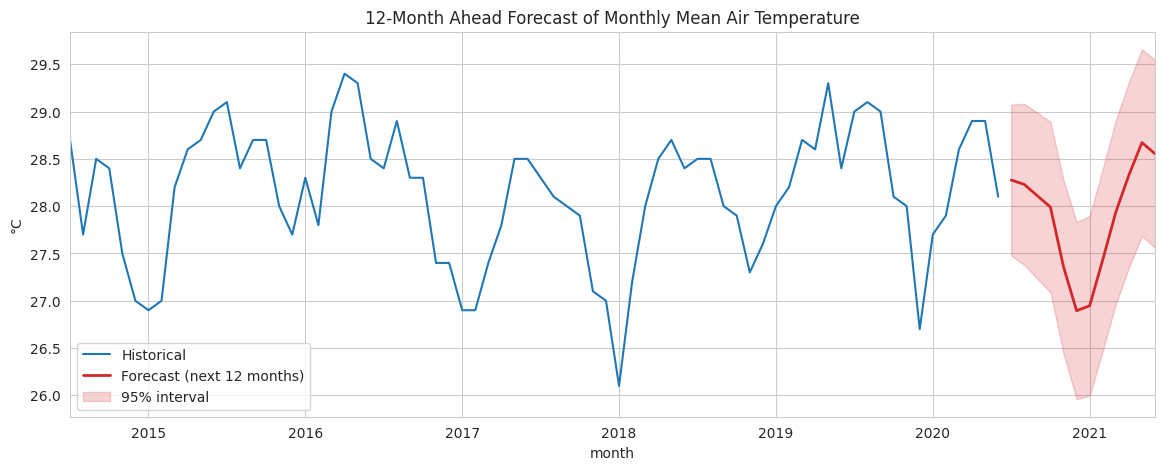

In [21]:
H = 12
fc_obj  = final_model.get_forecast(H)
fc_mean = fc_obj.predicted_mean
fc_ci   = fc_obj.conf_int(alpha=0.05)

forecast_df = pd.DataFrame({"forecast_mean_temp": fc_mean.round(2),
                            "lower_95": fc_ci.iloc[:, 0].round(2),
                            "upper_95": fc_ci.iloc[:, 1].round(2)})
forecast_df.index.name = "month"
display(forecast_df)

fig, ax = plt.subplots(figsize=(14, 5))
ts.iloc[-72:].plot(ax=ax, color="tab:blue", label="Historical")
fc_mean.plot(ax=ax, color="tab:red", lw=2, label="Forecast (next 12 months)")
ax.fill_between(fc_ci.index, fc_ci.iloc[:, 0], fc_ci.iloc[:, 1], color="tab:red", alpha=0.2, label="95% interval")
ax.set_title("12-Month Ahead Forecast of Monthly Mean Air Temperature"); ax.set_ylabel("°C"); ax.legend()
plt.show()

## 10. Save the Model & Forecast

In [22]:
os.makedirs("outputs", exist_ok=True)
joblib.dump(final_model, "outputs/air_temp_sarima_model.pkl")
forecast_df.to_csv("outputs/next_12_months_forecast.csv")
res.to_csv("outputs/model_comparison.csv", index=False)

# Reload to confirm the saved model works
loaded = joblib.load("outputs/air_temp_sarima_model.pkl")
print(loaded.get_forecast(3).predicted_mean.round(2))

2020-07-01    28.28
2020-08-01    28.23
2020-09-01    28.11
Freq: MS, Name: predicted_mean, dtype: float64


## 11. Conclusion
- **Data:** 462 monthly observations (Jan 1982 – Jun 2020), no missing values, with a yearly seasonal cycle and a mild upward trend.
- **Approach:** Compared simple baselines, Holt-Winters, ARIMA, SARIMA and lag-feature ML models (Ridge, Random Forest), first on a 24-month hold-out and then with 5-fold rolling-origin cross-validation.
- **Key finding:** The single 24-month split favoured the Naive forecast, but cross-validation showed this was a quirk of that window. Across five 12-month windows, **Holt-Winters and SARIMA** were the most accurate (mean RMSE about 0.54 °C), ahead of the ML models, ARIMA and the Naive baseline.
- **Final model:** SARIMA, re-fitted on all data, forecasting the next 12 months (Jul 2020 – Jun 2021) with 95% intervals.
- **Limitations:** Typical forecast error is about 0.5–0.6 °C, which is large relative to the ~±0.5 °C seasonal swing, so the model captures the seasonal shape but not year-to-year anomalies. Ljung-Box tests show some leftover autocorrelation in the residuals. Only past temperature is used (no humidity, rainfall, El Niño/ENSO indices), and the data comes from a single station.
- **Next steps:** add exogenous drivers (ENSO index, rainfall), try Prophet / LSTM, ensemble Holt-Winters with SARIMA, and retrain monthly as new data arrives.